In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# 데이터 불러오기 : 기존 데이터
PATH='C:\\ex\\data\\21_cmapss_fd001_sample copy 2.csv'
df=pd.read_csv(PATH)

In [5]:
# 결측 확인 1 : .info()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1031 entries, 0 to 1030
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   unit_nr      1031 non-null   int64  
 1   time_cycles  1031 non-null   int64  
 2   setting_1    1031 non-null   float64
 3   setting_2    1031 non-null   float64
 4   setting_3    1031 non-null   float64
 5   s_2          1031 non-null   float64
 6   s_3          1031 non-null   float64
 7   s_4          1031 non-null   float64
 8   s_7          1031 non-null   float64
 9   s_11         1031 non-null   float64
dtypes: float64(8), int64(2)
memory usage: 80.7 KB


In [6]:
# 결측 확인 2 : .isna().sum().sum()
df.isna().sum().sum() # 총 결측 0

np.int64(0)

In [10]:
df.columns # [0]부터 [4]까지는 관심없는 컬럼(센서와 무관) -> 제외 대상

Index(['unit_nr', 'time_cycles', 'setting_1', 'setting_2', 'setting_3', 's_2',
       's_3', 's_4', 's_7', 's_11'],
      dtype='str')

In [12]:
# 센서 관련 컬럼만 추출
df_sensor=df.iloc[:,5:]

# 모든 컬럼을 하나의 리스트로 묶음 : .to_list()
cols=df_sensor.columns.to_list()

# 추출될 컬럼만 받을 리스트 밑작업
sensor=[]

for i in cols:
    if df[i].std() != 0: # 센서 중 변동성이 없는 것들은 걸러냄
        sensor.append(i) # 변동성이 있는 것만 리스트에 추가

print(sensor)

['s_2', 's_3', 's_4', 's_7', 's_11']


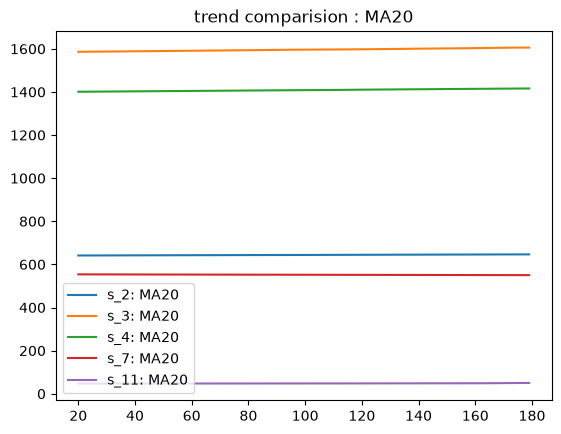

In [14]:
# 3번 엔진을 분석 대상으로
e3=df[df['unit_nr'] == 3].reset_index(drop=True)

# 각 센서에 대하여 window를 20으로 설정
# 사이클 별 센서의 이동 평균 도시
for col in sensor :
    plt.plot(e3['time_cycles'], e3[col].rolling(20).mean(), label=f'{col}: MA20')
plt.title('trend comparision : MA20')
plt.legend()
plt.show()
# 그림이 밋밋해서 추세가 명확하지 않음

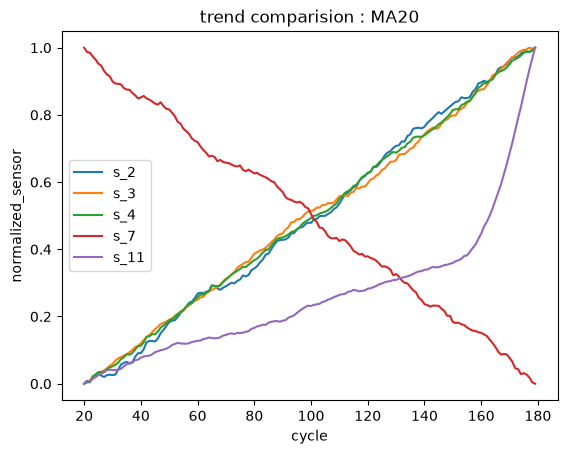

In [ ]:
# min-max 정규화 : 추세를 더 선명하게 도시
for col in sensor:
    ma = e3[col].rolling(20).mean()  # window=20의 이동평균
    plt.plot(e3['time_cycles'], (ma - ma.min()) / (ma.max() - ma.min()), label=col) # min-max 정규화 적용

plt.title('trend comparision : MA20')
plt.xlabel('cycle')
plt.ylabel('normalized_sensor')

plt.legend()
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_14040\859759341.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


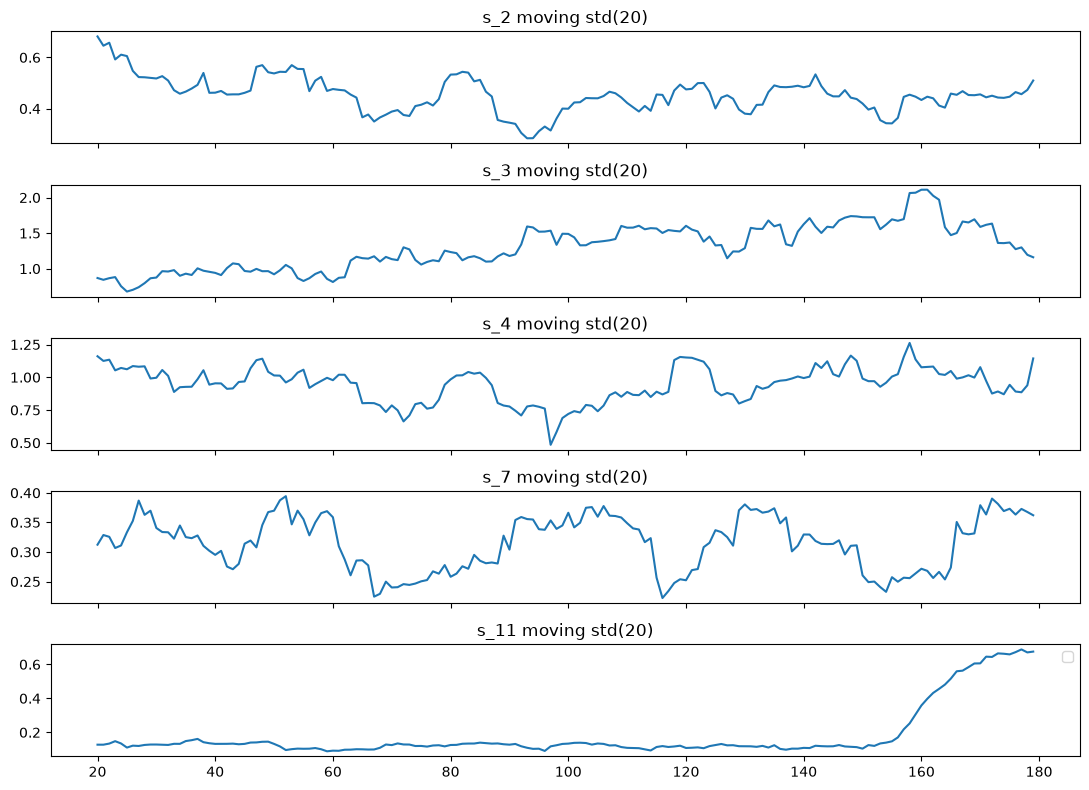

In [17]:
# 이동표준편차 : 변동성 파악
fig, axes = plt.subplots(5,1, figsize=(11,8), sharex=True)

# zip으로 axes와 sensor를 언패킹
for ax, col in zip(axes, sensor):
    ax.plot(e3['time_cycles'], e3[col].rolling(20).std()) # 각 ax에 대응되는 센서의 표준편차 시각화
    ax.set_title(col+" moving std(20)")

plt.tight_layout()
plt.legend()

plt.show()

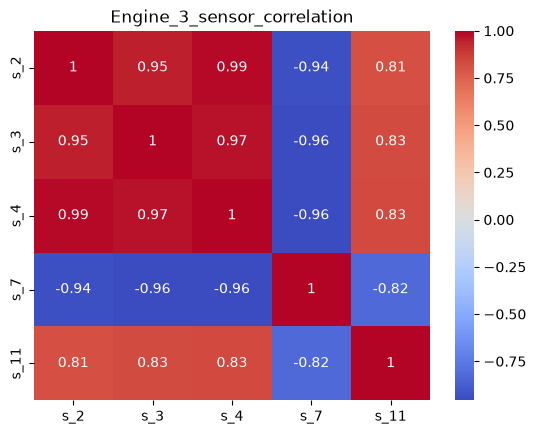

In [ ]:
# 센서 간 상관계수 시각화 : 히트맵
sns.heatmap(e3[sensor].corr(), annot=True, cmap='coolwarm')

plt.title('Engine_3_sensor_correlation')
plt.show()

In [21]:
sensor

['s_2', 's_3', 's_4', 's_7', 's_11']

In [ ]:
# 상관계수 표(corr)
corr = e3[sensor].corr()
pos_pairs = []
neg_pairs = []

for i in sensor:
    for j in corr.columns: # sensor와 같음
        if sensor.index(i) >= sensor.index(j):  # sensor 리스트의 왼쪽부터 0,1,2,3,4는 s_2, s_3, s_4, s_7, s_11에 해당
            continue # s_2 - s_2(자기 자신), s_2 - s_3(중복 쌍)을 건너뜀(continue)

        c = corr.loc[i, j] # corr라는 상관계수 표에 i,j를 매치했을 때 얻어지는 상관계수가 c에 저장됨

        if c >= 0.9: # 0.9 이상의 강한 양의 상관
            pos_pairs.append((i, j, round(c, 3))) # 만족 시, pos_pairs에 저장
        elif c <= -0.9: # -0.9~-0.1 사이의 강한 음의 상관
            neg_pairs.append((i, j, round(c, 3))) # 만족 시, neg_pairs에 저장

print('# 양의 상관 페어')
for i, j, c in pos_pairs:
    print(f'{i} - {j}: {c}')

print('-'*20)
print('# 음의 상관 페어')
for i, j, c in neg_pairs:
    print(f'{i} - {j}: {c}')

# 양의 상관 쌍
s_2 - s_3: 0.952
s_2 - s_4: 0.986
s_3 - s_4: 0.971
--------------------
# 음의 상관 쌍
s_2 - s_7: -0.938
s_3 - s_7: -0.956
s_4 - s_7: -0.957
